<a href="https://colab.research.google.com/github/janeethayasmin018-eng/workora-labs/blob/main/Churn_Prediction_Colab.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Predictive Churn Analysis
Classification pipeline (Logistic Regression + Random Forest) to forecast customer churn probability.

**Steps:** 1) Load data & encode (One-Hot, MinMax) → 2) 80/20 split → 3) Train models → 4) Evaluate (Precision, Recall, F1, ROC-AUC) → 5) Export churn risk scores

**Before running:** Runtime → Run all. When prompted in Step 1, upload `customer_churn_model_v2.csv`.

## 1. Setup & load data

In [1]:
import os, json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.compose import ColumnTransformer
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (classification_report, confusion_matrix, ConfusionMatrixDisplay,
                             f1_score, precision_score, recall_score, roc_auc_score, roc_curve)
from sklearn.model_selection import StratifiedKFold, cross_val_score, train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import MinMaxScaler, OneHotEncoder

SEED = 42
DATA_FILE = "customer_churn_model_v2.csv"
TARGET, ID_COL = "Churn", "CustomerID"

In [2]:
# Upload the CSV (skipped if it is already in the Colab session)
if not os.path.exists(DATA_FILE):
    from google.colab import files
    uploaded = files.upload()          # pick customer_churn_model_v2.csv
    DATA_FILE = list(uploaded.keys())[0]

df = pd.read_csv(DATA_FILE)
print(df.shape)
df.head()

Saving customer_churn_model_v2.csv to customer_churn_model_v2.csv
(800, 13)


,CustomerID,Age,Region,TenureMonths,SubscriptionType,MonthlyChargesINR,TotalChargesINR,ContractType,SupportTickets,LatePayments,PaymentMethod,AutoPay,Churn
0,CUST-100001,57,South,33,Standard,767.25,23893.97,Month-to-Month,4,1,UPI,Yes,Yes
1,CUST-100002,44,South,45,Basic,476.72,21627.46,Two Year,0,1,UPI,Yes,Yes
2,CUST-100003,64,South,57,Basic,414.81,22500.07,One Year,1,1,UPI,No,Yes
3,CUST-100004,57,East,44,Pro,1171.76,50309.16,Month-to-Month,4,0,Card,Yes,Yes
4,CUST-100005,58,North,49,Pro,1130.19,55980.21,Month-to-Month,3,0,Wallet,No,No


In [12]:
from google.colab import sheets
sheet = sheets.InteractiveSheet(df=df)

MessageError: Error: credential propagation was unsuccessful

In [3]:
# Quick data check
print("Missing values:", int(df.isna().sum().sum()))
print("Churn rate: {:.1%}".format((df[TARGET] == "Yes").mean()))
df.describe(include="all").T

Missing values: 0
Churn rate: 41.8%


,count,unique,top,freq,mean,std,min,25%,50%,75%,max
CustomerID,800,800,CUST-100001,1,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Age,800.0,NaN,NaN,NaN,44.0,14.448822,18.0,32.0,44.0,56.0,68.0
Region,800,5,South,178,NaN,NaN,NaN,NaN,NaN,NaN,NaN
TenureMonths,800.0,NaN,NaN,NaN,37.23,20.467003,0.0,19.75,37.0,56.0,72.0
SubscriptionType,800,3,Basic,278,NaN,NaN,NaN,NaN,NaN,NaN,NaN
MonthlyChargesINR,800.0,NaN,NaN,NaN,747.905125,288.4257,364.47,451.445,717.46,1093.01,1183.96
TotalChargesINR,800.0,NaN,NaN,NaN,27440.590013,19421.452781,0.0,12521.705,23661.635,38513.11,83229.0
ContractType,800,3,Month-to-Month,432,NaN,NaN,NaN,NaN,NaN,NaN,NaN
SupportTickets,800.0,NaN,NaN,NaN,1.83625,1.437713,0.0,1.0,2.0,3.0,6.0
LatePayments,800.0,NaN,NaN,NaN,1.32,1.136536,0.0,0.0,1.0,2.0,5.0


## 2. Feature encoding & 80/20 split
One-Hot encoding for categorical columns, MinMax scaling for numeric columns. Both are placed inside a `Pipeline`, so they are fitted on the **training data only** (no data leakage). The split is stratified to keep the churn ratio equal in train and test.

In [4]:
ids = df[ID_COL]
y = (df[TARGET].astype(str).str.strip().str.lower() == "yes").astype(int)
X = df.drop(columns=[TARGET, ID_COL])

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=SEED, stratify=y)
print("Train:", X_train.shape, "| Test:", X_test.shape)

num_cols = X.select_dtypes(include="number").columns.tolist()
cat_cols = X.select_dtypes(exclude="number").columns.tolist()
print("Numeric:", num_cols)
print("Categorical:", cat_cols)

preprocess = ColumnTransformer([
    ("num", MinMaxScaler(), num_cols),
    ("cat", OneHotEncoder(handle_unknown="ignore"), cat_cols),
])

Train: (640, 11) | Test: (160, 11)
Numeric: ['Age', 'TenureMonths', 'MonthlyChargesINR', 'TotalChargesINR', 'SupportTickets', 'LatePayments']
Categorical: ['Region', 'SubscriptionType', 'ContractType', 'PaymentMethod', 'AutoPay']


## 3. Train models

In [5]:
models = {
    "Logistic Regression": LogisticRegression(max_iter=1000, class_weight="balanced", random_state=SEED),
    "Random Forest": RandomForestClassifier(n_estimators=300, min_samples_leaf=5,
                                            class_weight="balanced", random_state=SEED, n_jobs=-1),
}

cv = StratifiedKFold(5, shuffle=True, random_state=SEED)
fitted, cv_scores = {}, {}
for name, clf in models.items():
    pipe = Pipeline([("prep", preprocess), ("clf", clf)])
    cv_scores[name] = cross_val_score(pipe, X_train, y_train, cv=cv, scoring="roc_auc")
    fitted[name] = pipe.fit(X_train, y_train)
    print(f"{name}: trained | 5-fold CV ROC-AUC = {cv_scores[name].mean():.3f} +/- {cv_scores[name].std():.3f}")

Logistic Regression: trained | 5-fold CV ROC-AUC = 0.700 +/- 0.030
Random Forest: trained | 5-fold CV ROC-AUC = 0.709 +/- 0.033


## 4. Evaluation: Precision, Recall, F1-Score, ROC-AUC

In [6]:
results, probas = {}, {}
for name, pipe in fitted.items():
    proba = pipe.predict_proba(X_test)[:, 1]
    pred = (proba >= 0.5).astype(int)
    probas[name] = proba
    results[name] = {
        "Precision": precision_score(y_test, pred),
        "Recall": recall_score(y_test, pred),
        "F1-Score": f1_score(y_test, pred),
        "ROC-AUC": roc_auc_score(y_test, proba),
        "CV ROC-AUC": cv_scores[name].mean(),
    }
    print(f"===== {name} =====")
    print(classification_report(y_test, pred, target_names=["Stayed", "Churned"]))

summary = pd.DataFrame(results).T.round(3)
summary

===== Logistic Regression =====
              precision    recall  f1-score   support

      Stayed       0.76      0.62      0.69        93
     Churned       0.58      0.73      0.65        67

    accuracy                           0.67       160
   macro avg       0.67      0.68      0.67       160
weighted avg       0.69      0.67      0.67       160

===== Random Forest =====
              precision    recall  f1-score   support

      Stayed       0.73      0.65      0.69        93
     Churned       0.58      0.67      0.62        67

    accuracy                           0.66       160
   macro avg       0.65      0.66      0.65       160
weighted avg       0.67      0.66      0.66       160



,Precision,Recall,F1-Score,ROC-AUC,CV ROC-AUC
Logistic Regression,0.583,0.731,0.649,0.681,0.700
Random Forest,0.577,0.672,0.621,0.687,0.709


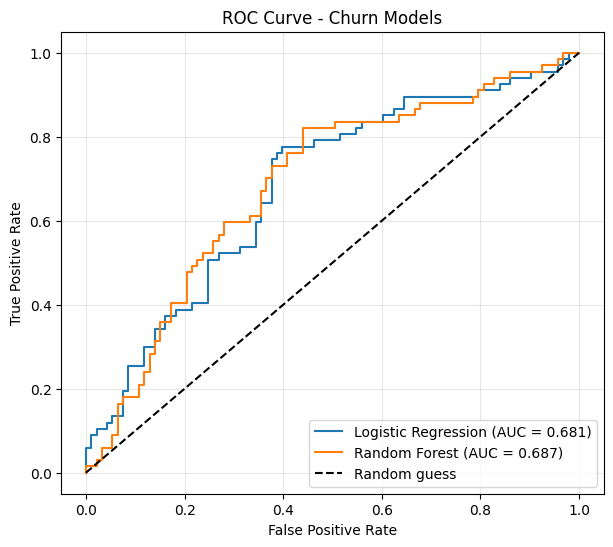

In [7]:
# ROC curves
plt.figure(figsize=(7, 6))
for name, proba in probas.items():
    fpr, tpr, _ = roc_curve(y_test, proba)
    plt.plot(fpr, tpr, label=f"{name} (AUC = {results[name]['ROC-AUC']:.3f})")
plt.plot([0, 1], [0, 1], "k--", label="Random guess")
plt.xlabel("False Positive Rate"); plt.ylabel("True Positive Rate")
plt.title("ROC Curve - Churn Models"); plt.legend(loc="lower right"); plt.grid(alpha=0.3)
plt.savefig("roc_curve.png", dpi=150, bbox_inches="tight")
plt.show()

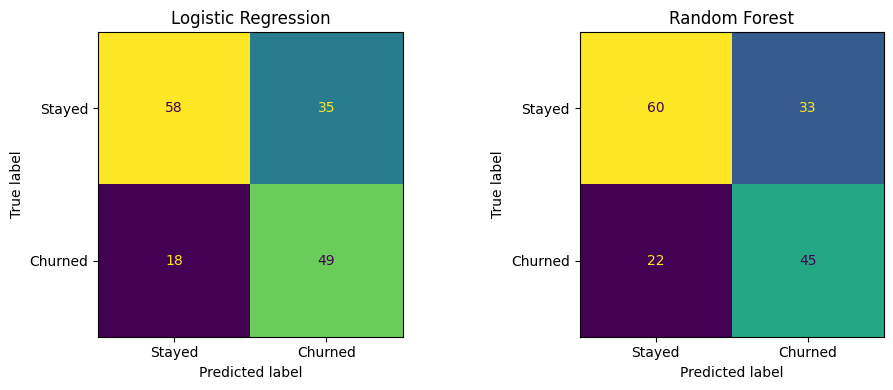

In [8]:
# Confusion matrices
fig, axes = plt.subplots(1, 2, figsize=(10, 4))
for ax, (name, proba) in zip(axes, probas.items()):
    ConfusionMatrixDisplay(confusion_matrix(y_test, (proba >= 0.5).astype(int)),
                           display_labels=["Stayed", "Churned"]).plot(ax=ax, colorbar=False)
    ax.set_title(name)
plt.tight_layout(); plt.show()

Best model by test ROC-AUC: Random Forest
Selected model: Logistic Regression


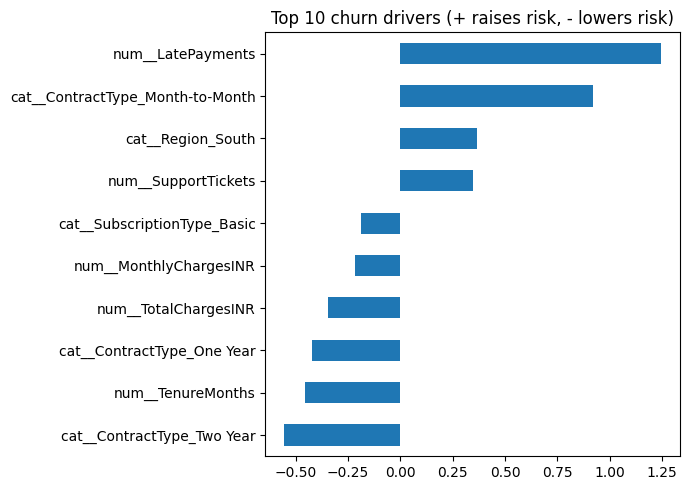

In [9]:
# Top churn drivers from the best model
best = summary["ROC-AUC"].idxmax()
print("Best model by test ROC-AUC:", best)
# If tied, prefer the interpretable Logistic Regression
if summary["ROC-AUC"].nunique() == 1 or abs(summary.loc["Logistic Regression", "ROC-AUC"] - summary["ROC-AUC"].max()) < 0.01:
    best = "Logistic Regression"
print("Selected model:", best)

names = fitted[best].named_steps["prep"].get_feature_names_out()
clf = fitted[best].named_steps["clf"]
vals = clf.coef_[0] if hasattr(clf, "coef_") else clf.feature_importances_
drivers = pd.Series(vals, index=names)
drivers = drivers.reindex(drivers.abs().sort_values(ascending=False).index).head(10)
drivers.sort_values().plot.barh(figsize=(7, 5), title="Top 10 churn drivers (+ raises risk, - lowers risk)")
plt.tight_layout(); plt.show()

## 5. Export churn risk score predictions

In [10]:
probs = fitted[best].predict_proba(X)[:, 1]
scores = pd.DataFrame({
    ID_COL: ids,
    "churn_probability": probs.round(4),
    "risk_tier": pd.cut(probs, bins=[-0.001, 0.3, 0.6, 1.0], labels=["Low", "Medium", "High"]),
    "split": np.where(X.index.isin(X_test.index), "test", "train"),
    "actual_churn": y,
}).sort_values("churn_probability", ascending=False)

scores.to_csv("churn_risk_scores.csv", index=False)
summary.to_csv("model_metrics.csv")
print(scores.groupby("risk_tier", observed=True)["actual_churn"].agg(["count", "mean"]).rename(columns={"mean": "actual churn rate"}).round(3))
scores.head(10)

           count  actual churn rate
risk_tier                          
Low          241              0.174
Medium       236              0.381
High         323              0.625


,CustomerID,churn_probability,risk_tier,split,actual_churn
523,CUST-100524,0.8757,High,test,1
423,CUST-100424,0.8673,High,test,1
363,CUST-100364,0.8666,High,train,0
381,CUST-100382,0.8591,High,train,1
316,CUST-100317,0.8539,High,train,0
81,CUST-100082,0.8532,High,train,1
34,CUST-100035,0.8516,High,train,1
792,CUST-100793,0.8339,High,train,1
476,CUST-100477,0.8304,High,train,1
674,CUST-100675,0.8300,High,train,1


In [11]:
# Download outputs to your computer (for the GitHub repo / submission)
try:
    from google.colab import files
    for f in ["churn_risk_scores.csv", "model_metrics.csv", "roc_curve.png"]:
        files.download(f)
except ImportError:
    pass

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

## 6. Report / Interpretation
*(Edit these notes after you run the notebook and see your own numbers.)*

- **Data:** 800 customers, 11 features, ~42% churn; no missing values.
- **Method:** One-Hot + MinMax inside a Pipeline, stratified 80/20 split, class-weight balancing for the churn minority class.
- **Performance:** Test ROC-AUC is about 0.68 for both models (5-fold CV about 0.70). This is better than chance (0.5), but the signal is modest.
- **Model choice:** Performance is nearly identical, so Logistic Regression is preferred for interpretability.
- **Drivers:** More late payments, month-to-month contracts, more support tickets raise churn risk; longer tenure and 1-2 year contracts lower it.
- **Limitations:** Only 160 test rows, so metrics are noisy; the 0.5 threshold favours recall and should be tuned to the cost of retention offers; scores for training-split customers are optimistic.
- **Next steps:** Threshold tuning, hyperparameter search, more behavioural features.